# Brain Tumor MRI Classification

CNN classifier for 4 classes of brain MRI scans: glioma, meningioma, no tumor, pituitary.
Dataset: Kaggle `tombackert/brain-tumor-mri-data` (7,153 images).

## 1. Setup

In [1]:
import os

import matplotlib.pyplot as plt
import pandas as pd
import torch
from PIL import Image
from sklearn.model_selection import train_test_split
from torch import nn
from torch.utils.data import DataLoader, Dataset
from torchvision import transforms

In [2]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(torch.__version__, device)
if torch.cuda.is_available():
    print(torch.cuda.get_device_name(0))

2.14.1+cu126 cuda
NVIDIA GeForce RTX 3050 6GB Laptop GPU


## 2. Load the data

In [3]:
data_path = r"C:\Users\prabh\Downloads\brain-tumor-mri-dataset"

for folder in os.listdir(data_path):
    folder_path = os.path.join(data_path, folder)
    print(folder, len(os.listdir(folder_path)))

glioma 1621
meningioma 1775
notumor 2000
pituitary 1757


In [4]:
data = []

for folder in os.listdir(data_path):
    folder_path = os.path.join(data_path, folder)
    for image_name in os.listdir(folder_path):
        image_path = os.path.join(folder_path, image_name)
        record = {}
        record["path"] = image_path
        record['label'] = folder
        data.append(record)

df = pd.DataFrame(data=data)
print(len(df))
df['label'].value_counts()

7153


label
notumor       2000
meningioma    1775
pituitary     1757
glioma        1621
Name: count, dtype: int64

## 2b. Remove duplicate images

Some scans appear more than once (exact same file bytes). Duplicates spread across splits leak training images into validation/test, so we drop them **before** splitting.

In [5]:
import hashlib

def file_hash(path):
    with open(path, "rb") as f:
        data = f.read()
    return hashlib.md5(data).hexdigest()

In [6]:
df["hash"] = df["path"].map(file_hash)
print(len(df), df["hash"].nunique())

7153 6726


In [7]:
labels_per_hash = df.groupby("hash")["label"].nunique()
conflicts = labels_per_hash[labels_per_hash > 1]
print(len(conflicts))
print(labels_per_hash.value_counts())  # should be one row: 1 -> 6726

0
label
1    6726
Name: count, dtype: int64


In [8]:
clean_df = df.drop_duplicates(subset="hash")
print(len(clean_df))
print(df["label"].value_counts())
print(clean_df["label"].value_counts())

6726
label
notumor       2000
meningioma    1775
pituitary     1757
glioma        1621
Name: count, dtype: int64
label
pituitary     1740
notumor       1731
meningioma    1635
glioma        1620
Name: count, dtype: int64


## 3. Explore the images

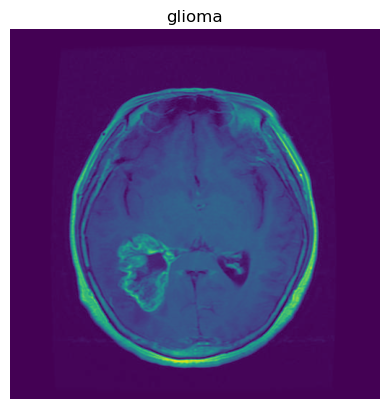

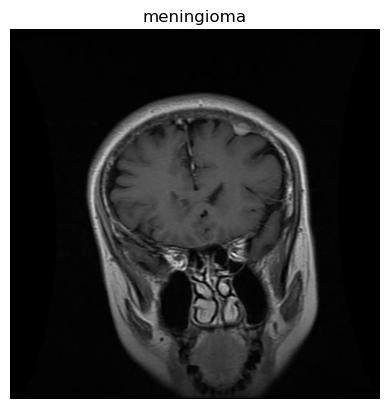

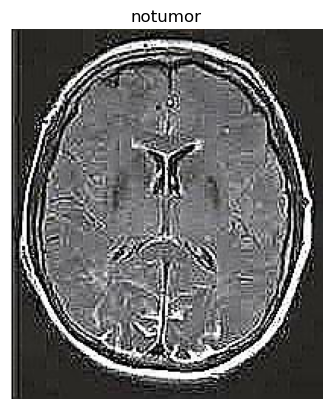

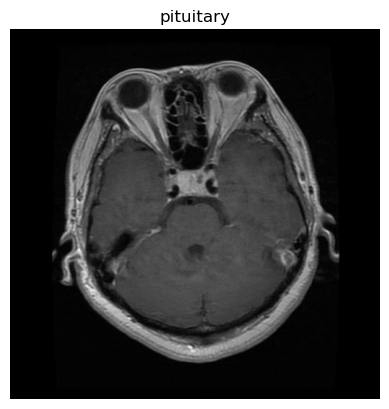

In [9]:
for folder in os.listdir(data_path):
    folder_path = os.path.join(data_path, folder)

    image_name = os.listdir(folder_path)[0]
    image_path = os.path.join(folder_path, image_name)

    image = plt.imread(image_path)

    plt.imshow(image)
    plt.title(folder)
    plt.axis("off")
    plt.show()

In [10]:
# image sizes and channel counts vary a lot (some grayscale, some RGB)
for folder in os.listdir(data_path):
    folder_path = os.path.join(data_path, folder)

    shapes = set()

    for image_name in os.listdir(folder_path)[:100]:
        image_path = os.path.join(folder_path, image_name)
        image = plt.imread(image_path)
        shapes.add(image.shape)

    print(folder, shapes)

glioma {(512, 512), (512, 512, 3)}
meningioma {(510, 485, 3), (336, 264, 3), (512, 512), (396, 411, 3), (237, 212, 3), (356, 286, 3), (216, 224, 3), (512, 512, 3), (365, 306, 3), (395, 366, 3), (342, 290, 3), (284, 324, 3), (306, 278, 3), (216, 234, 3), (1427, 1275, 3), (358, 314, 3)}
notumor {(168, 300, 3), (444, 468, 3), (674, 648, 3), (250, 201, 3), (442, 442, 3), (848, 785, 3), (442, 400, 3), (415, 339, 3), (225, 225, 3), (244, 235, 3), (243, 207, 3), (540, 504, 3), (250, 236, 3), (248, 208, 3), (340, 339, 3), (417, 428, 3), (275, 220, 3), (630, 630, 3), (310, 329, 3), (252, 200, 3), (449, 359, 3), (228, 235, 3), (236, 214, 3), (282, 230, 3), (236, 236, 3), (262, 227, 3), (244, 206, 3), (201, 173, 3), (257, 236, 3), (221, 228, 3), (649, 926, 3), (512, 512, 3), (680, 680, 3), (217, 232, 3), (664, 550, 3), (600, 494, 3), (234, 218, 3), (1024, 1024), (257, 196, 3), (238, 212, 3), (400, 393, 3), (251, 201, 3), (234, 215, 3), (294, 236, 3), (280, 420, 3), (192, 192, 3), (222, 227, 3), (

## 4. Train / validation / test split (70 / 15 / 15, stratified)

In [11]:
train_df, temp_df = train_test_split(clean_df, test_size=0.3, random_state=42, stratify=clean_df['label'])
validation_df, test_df = train_test_split(temp_df, test_size=.5, random_state=42, stratify=temp_df['label'])

print(len(train_df), len(validation_df), len(test_df))

4708 1009 1009


In [12]:
for name, split in [("train", train_df), ("validation", validation_df), ("test", test_df)]:
    print(name)
    print(split['label'].value_counts(), "\n")

train
label
pituitary     1218
notumor       1212
meningioma    1144
glioma        1134
Name: count, dtype: int64 

validation
label
pituitary     261
notumor       260
meningioma    245
glioma        243
Name: count, dtype: int64 

test
label
pituitary     261
notumor       259
meningioma    246
glioma        243
Name: count, dtype: int64 



### Leak check: no scan should appear in more than one split

In [13]:
train_df["hash"] = train_df["path"].map(file_hash)
validation_df["hash"] = validation_df["path"].map(file_hash)
test_df["hash"] = test_df["path"].map(file_hash)

In [14]:
train_hashes = set(train_df["hash"])
val_hashes = set(validation_df["hash"])
test_hashes = set(test_df["hash"])

print(len(train_df), len(train_hashes))

4708 4708


In [15]:
train_val_overlap = train_hashes & val_hashes
train_test_overlap = train_hashes & test_hashes
val_test_overlap = val_hashes & test_hashes

print(len(train_val_overlap), len(train_test_overlap), len(val_test_overlap))

0 0 0


In [16]:
leaked = validation_df["hash"].isin(train_hashes)
print(leaked.sum(), "of", len(validation_df))

0 of 1009


## 5. Labels to numbers

In [17]:
classes = sorted(df['label'].unique())

label_to_idx = dict()
for i, name in enumerate(classes):
    label_to_idx[name] = i

idx_to_label = {}
for name, i in label_to_idx.items():
    idx_to_label[i] = name

print(label_to_idx)
print(idx_to_label)

{'glioma': 0, 'meningioma': 1, 'notumor': 2, 'pituitary': 3}
{0: 'glioma', 1: 'meningioma', 2: 'notumor', 3: 'pituitary'}


In [18]:
train_df['label_idx'] = train_df['label'].map(label_to_idx)
validation_df['label_idx'] = validation_df['label'].map(label_to_idx)
test_df['label_idx'] = test_df['label'].map(label_to_idx)

# should all be 0: every label found a match
print(train_df['label_idx'].isna().sum(), validation_df['label_idx'].isna().sum(), test_df['label_idx'].isna().sum())

0 0 0


## 6. Dataset class

In [19]:
class MRIDataset(Dataset):
    def __init__(self, df, transform=None):
        self.df = df.reset_index(drop=True)
        self.transform = transform

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        row = self.df.iloc[idx]
        path = row['path']
        label = row['label_idx']
        img = Image.open(path)
        img = img.convert("RGB")
        if self.transform is not None:
            img = self.transform(img)
        return img, label

## 7. Transforms

In [20]:
# training: resize + light augmentation + ImageNet normalization
train_transform = transforms.Compose([
    transforms.Resize((224, 224)),   # every image becomes 224x224
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(10),
    transforms.ToTensor(),           # PIL image -> tensor, pixel values 0-255 scaled to 0-1
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]),
])

# validation / test: same preprocessing, no randomness
eval_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]),
])

## 8. Datasets and loaders

In [21]:
train_ds = MRIDataset(train_df, transform=train_transform)
validation_ds = MRIDataset(validation_df, transform=eval_transform)
test_ds = MRIDataset(test_df, transform=eval_transform)

train_loader = DataLoader(train_ds, batch_size=32, shuffle=True)
validation_loader = DataLoader(validation_ds, batch_size=32, shuffle=False)
test_loader = DataLoader(test_ds, batch_size=32, shuffle=False)

print(len(train_loader), len(validation_loader), len(test_loader))

148 32 32


## 9. Check a batch

In [22]:
images, labels = next(iter(train_loader))
print(images.shape)   # [32, 3, 224, 224]
print(labels.shape)   # [32]
print(images.min().item(), images.max().item())

torch.Size([32, 3, 224, 224])
torch.Size([32])
-2.1179039478302 2.640000104904175


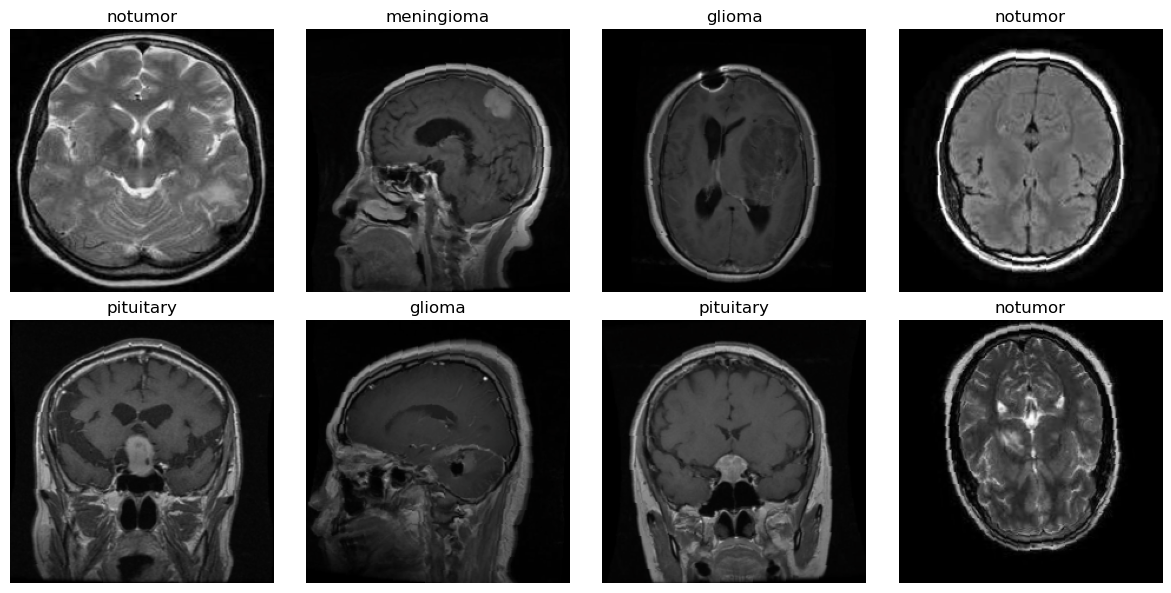

In [23]:
# undo the normalization just for plotting
mean = torch.tensor([0.485, 0.456, 0.406]).view(3, 1, 1)
std = torch.tensor([0.229, 0.224, 0.225]).view(3, 1, 1)

fig, axes = plt.subplots(2, 4, figsize=(12, 6))

for i, ax in enumerate(axes.flat):
    img = images[i] * std + mean
    label_name = idx_to_label[labels[i].item()]

    ax.imshow(img.permute(1, 2, 0).clamp(0, 1))
    ax.set_title(label_name)
    ax.axis("off")

plt.tight_layout()
plt.show()

## 10. Baseline CNN

In [24]:
model = nn.Sequential(
    nn.Conv2d(in_channels=3, out_channels=16, kernel_size=3, padding=1),
    nn.ReLU(),
    nn.MaxPool2d(kernel_size=2, stride=2),
    nn.Conv2d(in_channels=16, out_channels=32, kernel_size=3, padding=1),
    nn.ReLU(),
    nn.MaxPool2d(kernel_size=2, stride=2),
    nn.Flatten(),
    nn.Linear(in_features=32 * 56 * 56, out_features=4)
)
model.to(device)

print(sum(p.numel() for p in model.parameters()))

406500


## 11. Train (10 epochs, keep the best epoch by validation loss)

In [25]:
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(params=model.parameters(), lr=1e-3)

In [26]:
best_val = float("inf")
best_epoch = 0
train_losses = []
val_losses = []
val_accs = []

for epoch in range(1, 11):
    # ---- training ----
    model.train()
    running_loss = 0
    for images, labels in train_loader:
        images = images.to(device)
        labels = labels.to(device)
        optimizer.zero_grad()           # clear old gradients
        logits = model(images)          # compute scores
        loss = criterion(logits, labels)
        loss.backward()                 # backpropagate gradients
        optimizer.step()                # update weights
        running_loss += loss.item() * len(labels)
    train_loss = running_loss / len(train_ds)

    # ---- validation ----
    model.eval()
    total_loss = 0
    correct = 0

    with torch.no_grad():
        for images, labels in validation_loader:
            images = images.to(device)
            labels = labels.to(device)
            logits = model(images)
            loss = criterion(logits, labels)

            total_loss += loss.item() * len(labels)
            preds = logits.argmax(dim=1)
            correct += (preds == labels).sum().item()

    val_loss = total_loss / len(validation_ds)
    val_acc = correct / len(validation_ds)

    # ---- keep the best epoch ----
    if val_loss < best_val:
        best_val = val_loss
        best_epoch = epoch
        best_state = {k: v.detach().clone() for k, v in model.state_dict().items()}

    # ---- save + print ----
    train_losses.append(train_loss)
    val_losses.append(val_loss)
    val_accs.append(val_acc)
    print(f"epoch {epoch}: train loss {train_loss:.3f} | val loss {val_loss:.3f} | val acc {val_acc:.1%}")

model.load_state_dict(best_state)   # restore the best weights
print(f"best epoch: {best_epoch}, val loss {best_val:.3f}")

epoch 1: train loss 1.285 | val loss 0.566 | val acc 77.9%
epoch 2: train loss 0.491 | val loss 0.410 | val acc 86.1%
epoch 3: train loss 0.409 | val loss 0.448 | val acc 83.3%
epoch 4: train loss 0.356 | val loss 0.346 | val acc 88.0%
epoch 5: train loss 0.299 | val loss 0.344 | val acc 88.4%
epoch 6: train loss 0.243 | val loss 0.295 | val acc 89.4%
epoch 7: train loss 0.224 | val loss 0.280 | val acc 90.7%
epoch 8: train loss 0.212 | val loss 0.284 | val acc 93.0%
epoch 9: train loss 0.189 | val loss 0.276 | val acc 92.6%
epoch 10: train loss 0.162 | val loss 0.262 | val acc 91.8%
best epoch: 10, val loss 0.262


## 12. Training curves

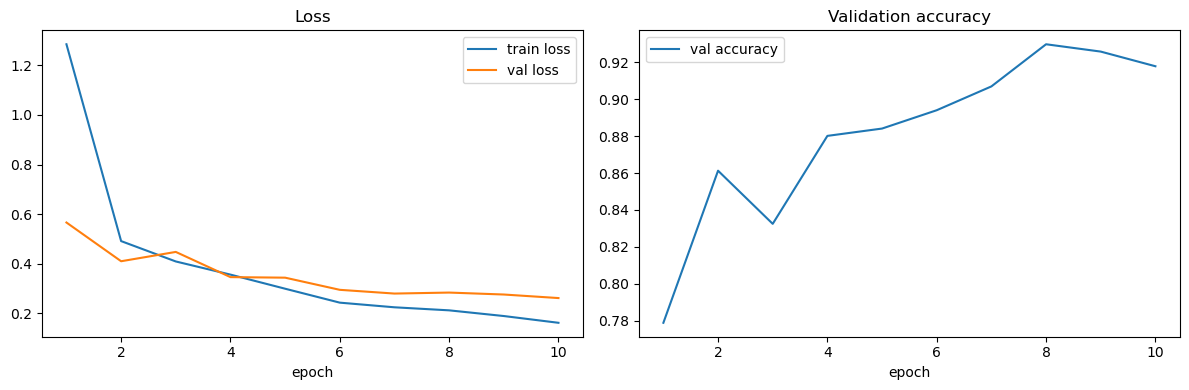

In [27]:
epochs = range(1, len(train_losses) + 1)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# left plot: loss
axes[0].plot(epochs, train_losses, label="train loss")
axes[0].plot(epochs, val_losses, label="val loss")
axes[0].set_xlabel("epoch")
axes[0].set_title("Loss")
axes[0].legend()

# right plot: validation accuracy
axes[1].plot(epochs, val_accs, label="val accuracy")
axes[1].set_xlabel("epoch")
axes[1].set_title("Validation accuracy")
axes[1].legend()

plt.tight_layout()
plt.show()

## 13. Save the best weights

In [28]:
torch.save(model.state_dict(), "baseline_cnn_best.pt")

In [35]:
from torchvision import models

resnet = models.resnet18(weights=models.ResNet18_Weights.DEFAULT)
print(resnet.fc)

Linear(in_features=512, out_features=1000, bias=True)


In [36]:
resnet.fc = nn.Linear(in_features=512, out_features=4)
print(resnet.fc)

Linear(in_features=512, out_features=4, bias=True)


In [37]:
resnet.to(device)
images, labels = next(iter(train_loader))
logits = resnet(images.to(device))
print(logits.shape)

torch.Size([32, 4])


In [38]:
resnet_optimizer = torch.optim.Adam(resnet.parameters(), lr=1e-4)

In [39]:
best_val = float("inf")
best_epoch = 0
resnet_train_losses = []
resnet_val_losses = []
resnet_val_accs = []

for epoch in range(1, 11):
    # ---- training ----
    resnet.train()
    running_loss = 0
    for images, labels in train_loader:
        images = images.to(device)
        labels = labels.to(device)
        resnet_optimizer.zero_grad()           # clear old gradients
        logits = resnet(images)          # compute scores
        loss = criterion(logits, labels)
        loss.backward()                 # backpropagate gradients
        resnet_optimizer.step()                # update weights
        running_loss += loss.item() * len(labels)
    train_loss = running_loss / len(train_ds)

    # ---- validation ----
    resnet.eval()
    total_loss = 0
    correct = 0

    with torch.no_grad():
        for images, labels in validation_loader:
            images = images.to(device)
            labels = labels.to(device)
            logits = resnet(images)
            loss = criterion(logits, labels)

            total_loss += loss.item() * len(labels)
            preds = logits.argmax(dim=1)
            correct += (preds == labels).sum().item()

    val_loss = total_loss / len(validation_ds)
    val_acc = correct / len(validation_ds)

    # ---- keep the best epoch ----
    if val_loss < best_val:
        best_val = val_loss
        best_epoch = epoch
        best_state = {k: v.detach().clone() for k, v in resnet.state_dict().items()}

    # ---- save + print ----
    resnet_train_losses.append(train_loss)
    resnet_val_losses.append(val_loss)
    resnet_val_accs.append(val_acc)
    print(f"epoch {epoch}: train loss {train_loss:.3f} | val loss {val_loss:.3f} | val acc {val_acc:.1%}")

resnet.load_state_dict(best_state)   # restore the best weights
print(f"best epoch: {best_epoch}, val loss {best_val:.3f}")

epoch 1: train loss 0.270 | val loss 0.129 | val acc 95.4%
epoch 2: train loss 0.084 | val loss 0.102 | val acc 96.3%
epoch 3: train loss 0.070 | val loss 0.039 | val acc 99.0%
epoch 4: train loss 0.030 | val loss 0.088 | val acc 96.9%
epoch 5: train loss 0.029 | val loss 0.052 | val acc 98.4%
epoch 6: train loss 0.042 | val loss 0.043 | val acc 98.8%
epoch 7: train loss 0.022 | val loss 0.041 | val acc 98.5%
epoch 8: train loss 0.043 | val loss 0.032 | val acc 99.1%
epoch 9: train loss 0.019 | val loss 0.030 | val acc 99.0%
epoch 10: train loss 0.018 | val loss 0.052 | val acc 98.4%
best epoch: 9, val loss 0.030


In [41]:
torch.save(resnet.state_dict(), "resnet18_best.pt")

In [42]:
print(best_epoch, best_val)

9 0.030139776897672988


In [43]:
all_preds = []
all_labels = []

resnet.eval()
with torch.no_grad():
    for images, labels in test_loader:
        images = images.to(device)
        logits = resnet(images)
        preds = logits.argmax(dim=1)

        all_preds.extend(preds.cpu().tolist())
        all_labels.extend(labels.tolist())

correct = sum(p == l for p, l in zip(all_preds, all_labels))
print(f"test accuracy: {correct / len(all_labels):.1%}  ({correct}/{len(all_labels)})")

test accuracy: 99.0%  (999/1009)


[[241   2   0   0]
 [  3 242   0   1]
 [  0   2 257   0]
 [  0   2   0 259]]


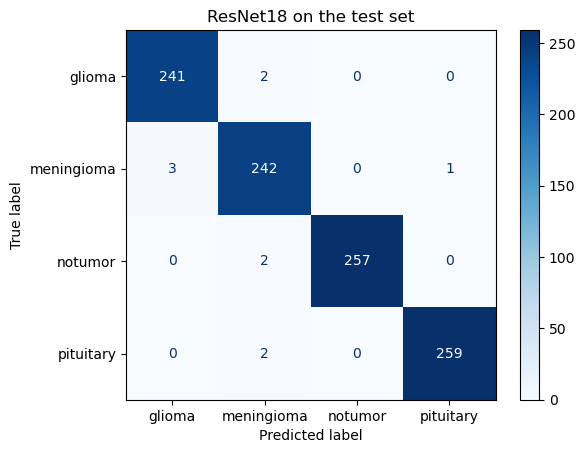

In [44]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

cm = confusion_matrix(all_labels,all_preds )
print(cm)

ConfusionMatrixDisplay(cm, display_labels=classes).plot(cmap="Blues")
plt.title("ResNet18 on the test set")
plt.show()

In [45]:
from sklearn.metrics import classification_report

print(classification_report(all_labels, all_preds, target_names=classes, digits=3))

              precision    recall  f1-score   support

      glioma      0.988     0.992     0.990       243
  meningioma      0.976     0.984     0.980       246
     notumor      1.000     0.992     0.996       259
   pituitary      0.996     0.992     0.994       261

    accuracy                          0.990      1009
   macro avg      0.990     0.990     0.990      1009
weighted avg      0.990     0.990     0.990      1009



In [46]:
%pip install grad-cam

  Installing build dependencies: started
  Installing build dependencies: finished with status 'done'
  Getting requirements to build wheel: started
  Getting requirements to build wheel: finished with status 'done'
  Preparing metadata (pyproject.toml): started
  Preparing metadata (pyproject.toml): finished with status 'done'
   ---------------------------------------- 0.0/47.8 MB ? eta -:--:--
   ---------------------------------------- 0.5/47.8 MB 4.0 MB/s eta 0:00:12
   -- ------------------------------------- 3.4/47.8 MB 11.2 MB/s eta 0:00:04
   ------ --------------------------------- 7.6/47.8 MB 15.2 MB/s eta 0:00:03
   ---------- ----------------------------- 12.8/47.8 MB 17.8 MB/s eta 0:00:02
   --------------- ------------------------ 18.1/47.8 MB 19.5 MB/s eta 0:00:02
   -------------------- ------------------- 24.1/47.8 MB 21.0 MB/s eta 0:00:02
   ------------------------- -------------- 30.9/47.8 MB 22.8 MB/s eta 0:00:01
   -------------------------------- ------- 38.5/47

In [47]:
from pytorch_grad_cam import GradCAM
from pytorch_grad_cam.utils.image import show_cam_on_image

target_layers = [resnet.layer4[-1]]
cam = GradCAM(model=resnet, target_layers=target_layers)



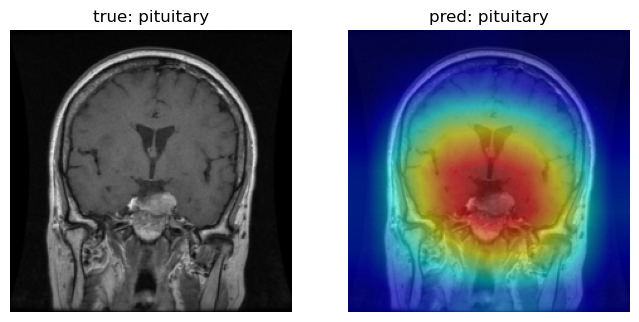

In [49]:
from pytorch_grad_cam.utils.model_targets import ClassifierOutputTarget

images, labels = next(iter(test_loader))
img = images[0:1].to(device)

pred = resnet(img).argmax(dim=1).item()
heat = cam(input_tensor=img, targets=[ClassifierOutputTarget(pred)])[0]

# undo normalization for display (same as your batch-plot cell)
rgb = (images[0] * std + mean).permute(1, 2, 0).clamp(0, 1).numpy()
overlay = show_cam_on_image(rgb, heat, use_rgb=True)

fig, axes = plt.subplots(1, 2, figsize=(8, 4))
axes[0].imshow(rgb)
axes[0].set_title(f"true: {idx_to_label[labels[0].item()]}")
axes[1].imshow(overlay)
axes[1].set_title(f"pred: {idx_to_label[pred]}")
for ax in axes: ax.axis("off")
plt.show()

In [50]:
def gradcam_overlay(image):
    img = image.unsqueeze(0).to(device)  
    pred = resnet(img).argmax(dim=1).item()
    heat = cam(input_tensor=img, targets=[ClassifierOutputTarget(pred)])[0]
    rgb = (image * std + mean).permute(1, 2, 0).clamp(0, 1).numpy()
    overlay = show_cam_on_image(rgb, heat, use_rgb=True)
    return overlay, pred


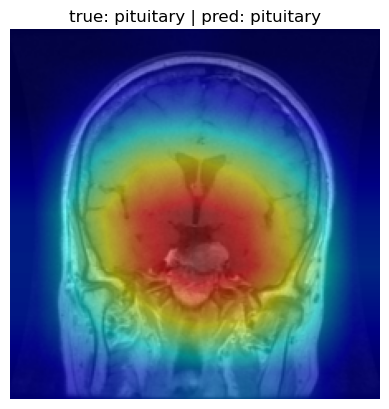

In [51]:
image, label = test_ds[0]
overlay, pred = gradcam_overlay(image)

plt.imshow(overlay)
plt.title(f"true: {idx_to_label[label]} | pred: {idx_to_label[pred]}")
plt.axis("off")
plt.show()

In [53]:
mistakes = [i for i in range(len(all_preds)) if all_preds[i] != all_labels[i]]
print(len(mistakes), mistakes)

10 [148, 248, 440, 524, 602, 627, 661, 717, 740, 891]


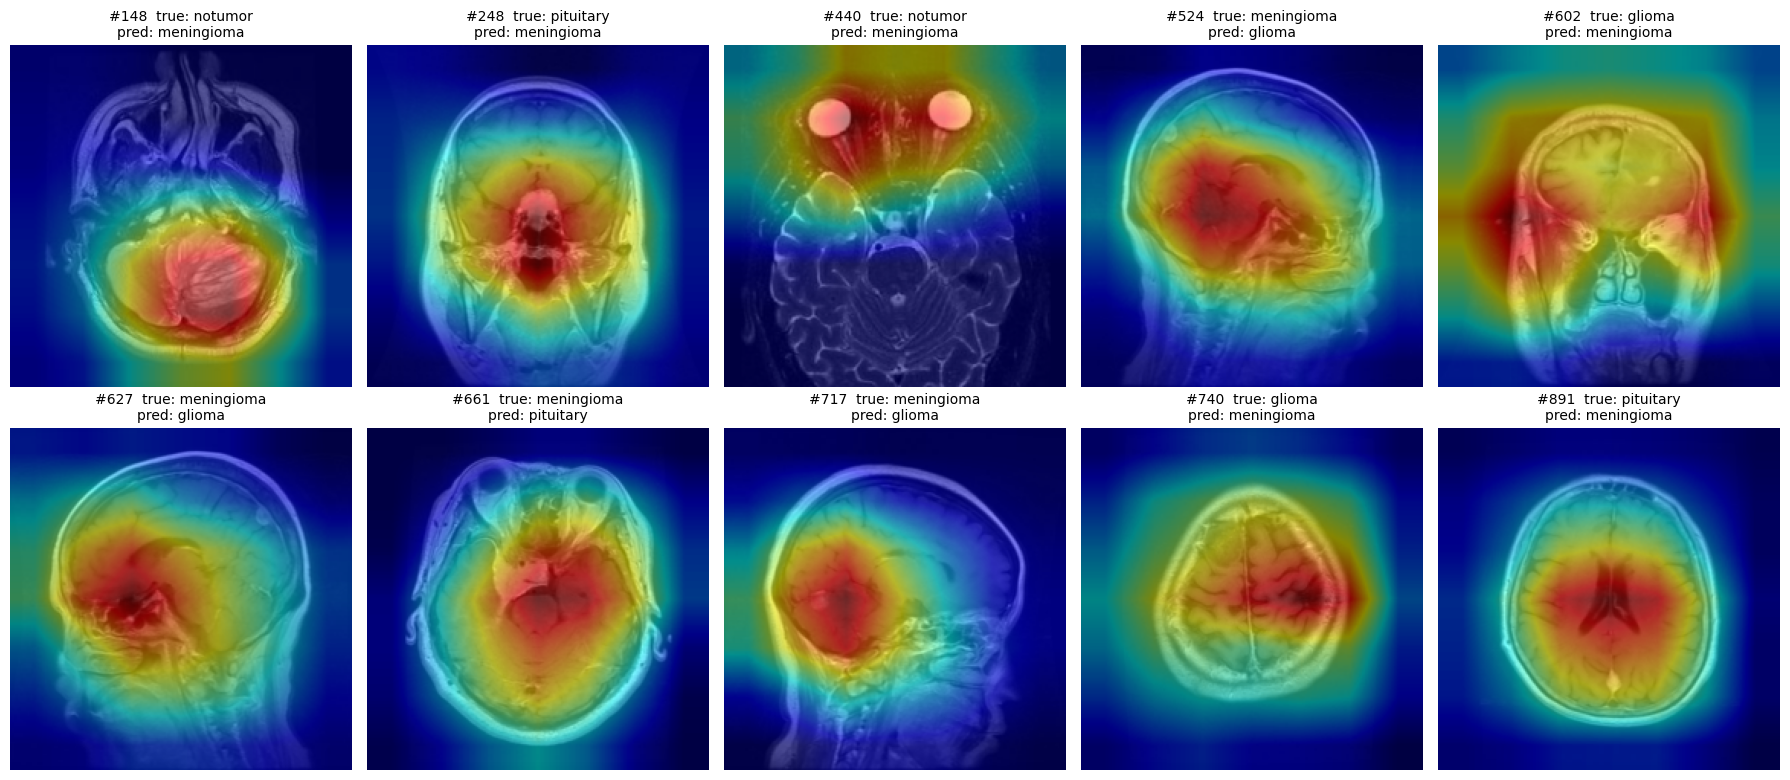

In [56]:
fig, axes = plt.subplots(2, 5, figsize=(18, 8))

for ax, i in zip(axes.flat, mistakes):
    image, label = test_ds[i]
    overlay, pred = gradcam_overlay(image)

    ax.imshow(overlay)
    ax.set_title(f"#{i}  true: {idx_to_label[label]}\npred: {idx_to_label[pred]}", fontsize=10)
    ax.axis("off")

plt.tight_layout()
plt.show()

In [57]:
correct_by_class = {}
for c in range(4):
    correct_by_class[c] = [i for i in range(len(all_preds))
                           if all_labels[i] == c and all_preds[i] == c][:4]
print(correct_by_class)

{0: [8, 15, 21, 25], 1: [4, 7, 18, 19], 2: [3, 5, 12, 13], 3: [0, 1, 2, 6]}


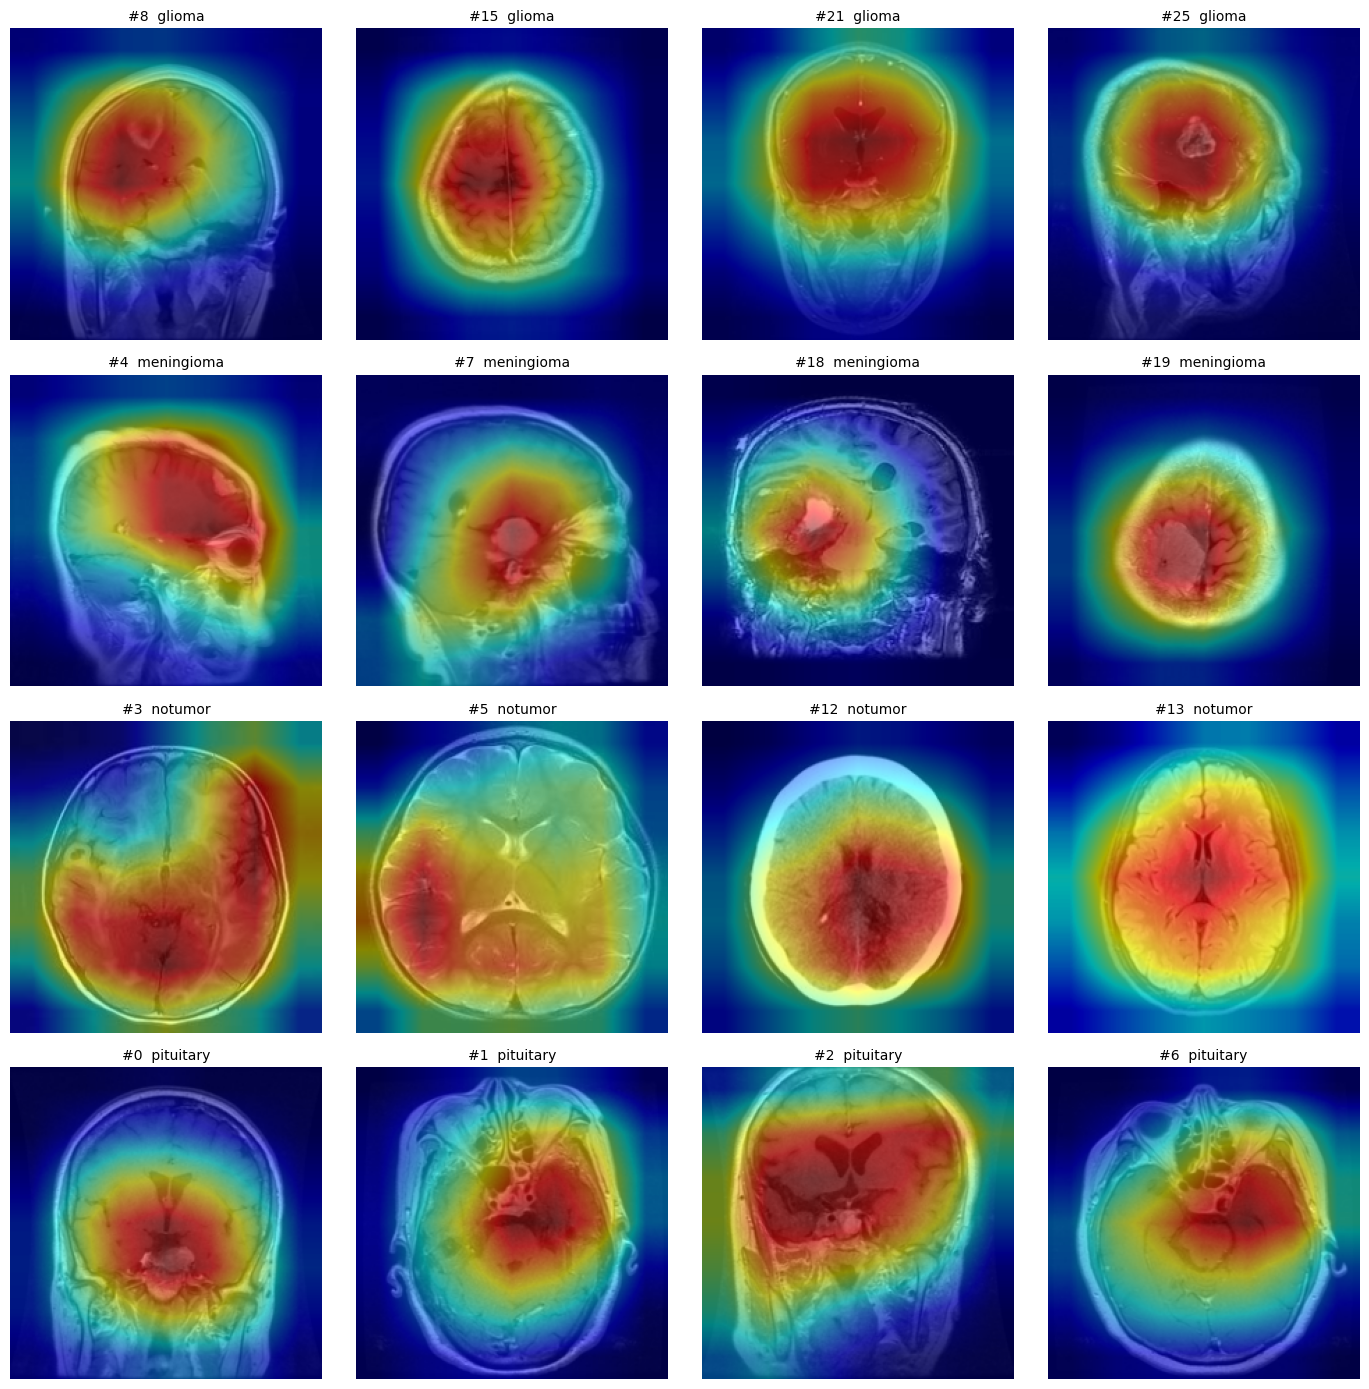

In [58]:
fig, axes = plt.subplots(4, 4, figsize=(14, 14))

for c in range(4):
    for j, i in enumerate(correct_by_class[c]):
        image, label = test_ds[i]
        overlay, pred = gradcam_overlay(image)

        ax = axes[c, j]
        ax.imshow(overlay)
        ax.set_title(f"#{i}  {idx_to_label[pred]}", fontsize=10)
        ax.axis("off")

plt.tight_layout()
plt.show()

In [59]:
import random

rng = random.Random(42)                      # fixed seed, so the sample is repeatable
sample_by_class = {}
for c in range(4):
    positions = [i for i in range(len(all_labels)) if all_labels[i] == c]
    sample_by_class[c] = sorted(rng.sample(positions, 20))

print({idx_to_label[c]: len(v) for c, v in sample_by_class.items()})

{'glioma': 20, 'meningioma': 20, 'notumor': 20, 'pituitary': 20}


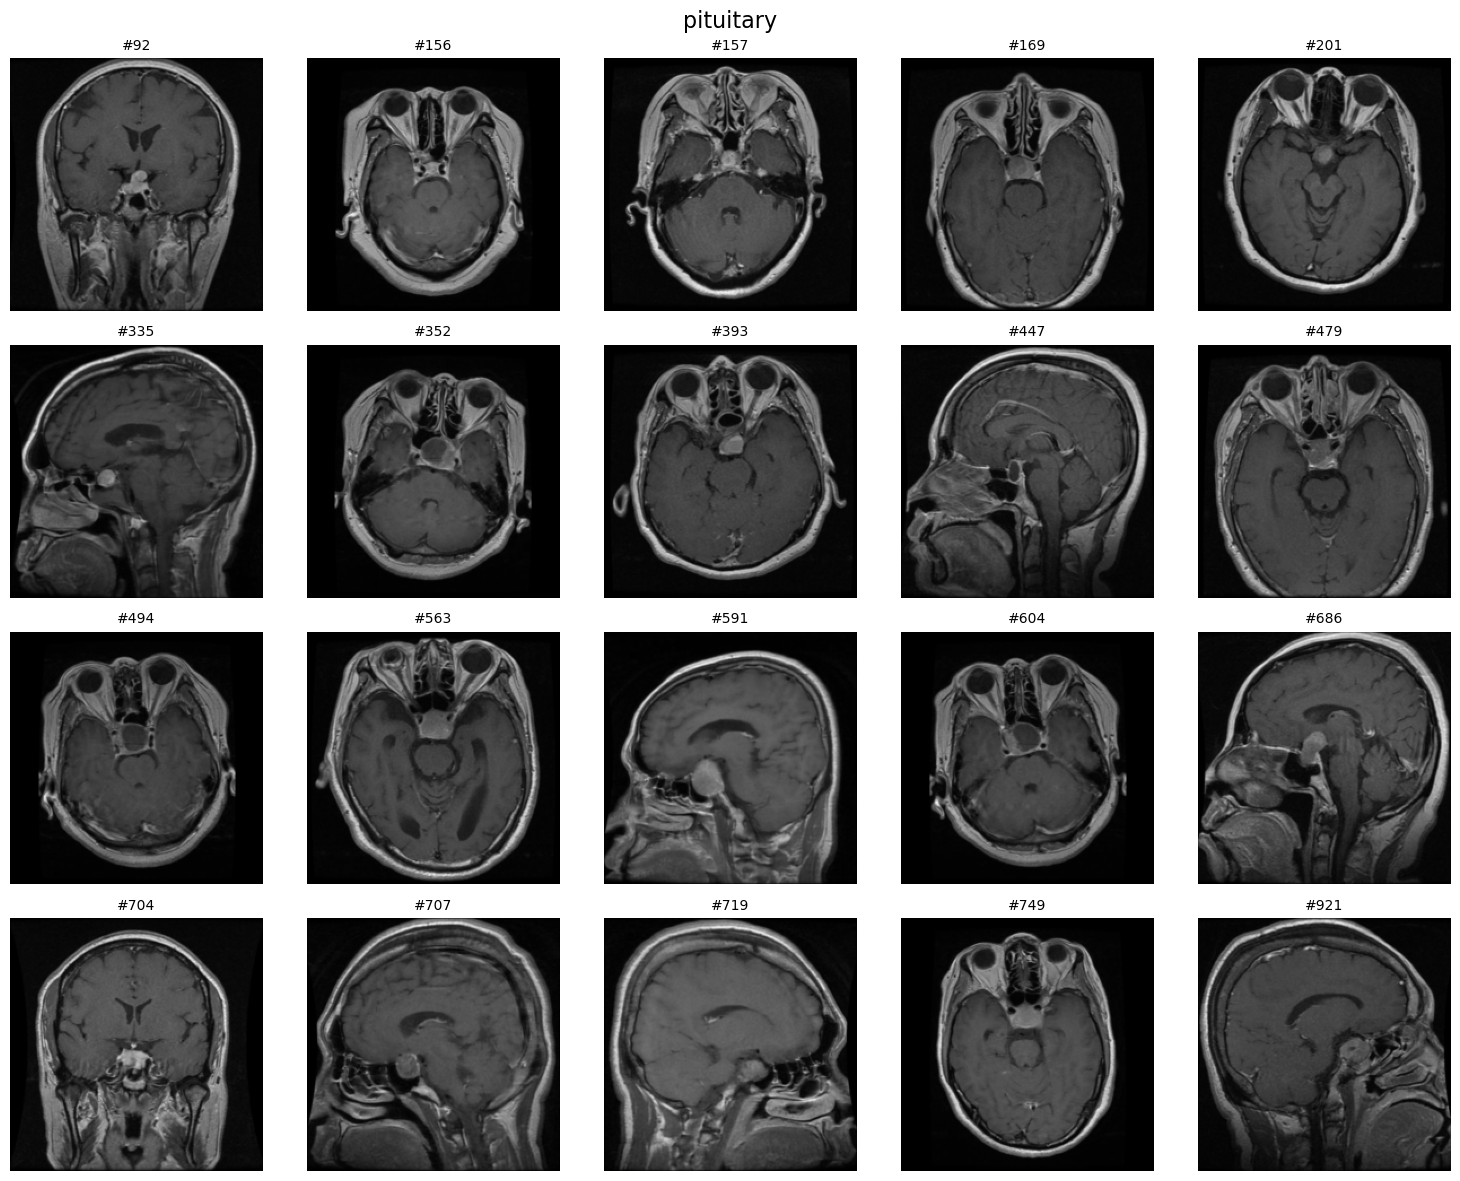

In [63]:
c = 3   # 0 = glioma, 1 = meningioma, 2 = notumor, 3 = pituitary

fig, axes = plt.subplots(4, 5, figsize=(15, 12))
for ax, i in zip(axes.flat, sample_by_class[c]):
    image, label = test_ds[i]
    rgb = (image * std + mean).permute(1, 2, 0).clamp(0, 1).numpy()
    ax.imshow(rgb)
    ax.set_title(f"#{i}", fontsize=10)
    ax.axis("off")
plt.suptitle(idx_to_label[c], fontsize=16)
plt.tight_layout()
plt.show()

In [64]:
views = {
    0: "ACAAACSCCCAAAACCSSAS",   # glioma
    1: "SSACAACCSSSASSSCASSS",   # meningioma
    2: "AAAAAAAAACCAAAAAAAAA",   # notumor
    3: "CAAAASAASAAASASCSSAS",   # pituitary
}

for c, s in views.items():
    assert len(s) == 20 and set(s) <= set("ACS"), f"class {c}: need exactly 20 letters, only A/C/S"
print("labels look good")

labels look good


In [65]:
rows = []
for c in range(4):
    for i, v in zip(sample_by_class[c], views[c]):
        rows.append({"pos": i, "class": idx_to_label[c], "view": v,
                     "correct": all_preds[i] == all_labels[i]})
audit = pd.DataFrame(rows)

print("Views per class (sample of 20 each):")
print(pd.crosstab(audit["class"], audit["view"]), "\n")

print("Accuracy by view:")
print(audit.groupby("view")["correct"].agg(["sum", "count"]), "\n")

axial_tumor = audit[(audit["class"] != "notumor") & (audit["view"] == "A")]
print(f"Axial tumor scans correct: {axial_tumor['correct'].sum()}/{len(axial_tumor)}")

Views per class (sample of 20 each):
view         A  C   S
class                
glioma       9  7   4
meningioma   5  4  11
notumor     18  2   0
pituitary   11  2   7 

Accuracy by view:
      sum  count
view            
A      42     43
C      15     15
S      22     22 

Axial tumor scans correct: 25/25
